# Module 10, Part 3: Inference optimization, caching, batching and export

This notebook is the runnable companion to Part 3 of the Module 10 learning content. Making a model fast in production is mostly about *not repeating work* and *sharing work between requests*. We measure both.

1. **The key-value cache** in a small decoder-only transformer: identical output, much less work per generated token, and what it costs in memory.
2. **Batching**: how the time for a batch grows with its size, and so why throughput rises while each request waits longer.
3. **A latency budget**: a simulated server with random arrivals, to find the batch size and waiting time that meet a target without wasting the hardware.
4. **ONNX export** and **ONNX Runtime**: that the exported model gives the same answers, and whether it is faster.

**Setting.** A two-layer, 64-dimensional decoder with 100 tokens (random weights: we are measuring cost, not quality), and the 64-512-512-10 digits classifier from Part 1. One CPU thread. Timings differ between machines, the shape of the results does not.

In [1]:
import copy, os, time, math
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
torch.set_num_threads(1)
INK, BODY, MUTED = "#14161B", "#4E5563", "#7C838C"
NAVY, GREEN, AMBER, KEY, RULE = "#1C3D6E", "#0E6B57", "#8A6A18", "#7A2E8A", "#D9DCE2"

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": RULE, "axes.labelcolor": BODY, "xtick.color": BODY, "ytick.color": BODY,
    "axes.grid": True, "grid.color": RULE, "font.size": 10,
})

In [2]:
import numpy as np
import torch
from sklearn.datasets import load_digits


def load_digits_split(seed=0, test_fraction=0.2):
    """Return (X_train, y_train, X_test, y_test). Pixels are scaled to [0, 1] and flattened to 64 values."""
    d = load_digits()
    X = (d.data / 16.0).astype(np.float32)
    y = d.target.astype(np.int64)
    rng = np.random.RandomState(seed)
    idx = rng.permutation(len(X))
    n_test = int(len(X) * test_fraction)
    te, tr = idx[:n_test], idx[n_test:]
    return torch.tensor(X[tr]), torch.tensor(y[tr]), torch.tensor(X[te]), torch.tensor(y[te])

In [3]:
import copy
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F


def mlp(sizes):
    layers = []
    for i in range(len(sizes) - 2):
        layers += [nn.Linear(sizes[i], sizes[i + 1]), nn.ReLU()]
    layers += [nn.Linear(sizes[-2], sizes[-1])]
    return nn.Sequential(*layers)


def accuracy(model, X, y):
    model.eval()
    with torch.no_grad():
        return (model(X).argmax(1) == y).float().mean().item()


def distill_loss(student_logits, teacher_logits, y, T=4.0, alpha=0.7):
    """alpha * T^2 * KL(teacher_T || student_T) + (1 - alpha) * cross entropy with the hard label."""
    soft = F.kl_div(F.log_softmax(student_logits / T, 1), F.softmax(teacher_logits / T, 1), reduction="batchmean") * T * T
    return alpha * soft + (1 - alpha) * F.cross_entropy(student_logits, y)


def train(model, X, y, epochs=60, lr=3e-3, batch=64, seed=0, teacher=None, T=4.0, alpha=0.7, masks=None, wd=0.0):
    """Train with cross entropy, or with the distillation loss when a teacher is given.
    `masks` (a list matching the Linear layers) are re-applied after every step so pruned weights stay zero."""
    g = torch.Generator().manual_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=wd)
    if teacher is not None:
        teacher.eval()
        with torch.no_grad():
            tl = teacher(X)
    lin = [m for m in model if isinstance(m, nn.Linear)]
    n = len(X)
    for ep in range(epochs):
        model.train()
        perm = torch.randperm(n, generator=g)
        for i in range(0, n, batch):
            b = perm[i:i + batch]
            out = model(X[b])
            loss = distill_loss(out, tl[b], y[b], T, alpha) if teacher is not None else F.cross_entropy(out, y[b])
            opt.zero_grad(); loss.backward(); opt.step()
            if masks is not None:
                with torch.no_grad():
                    for m, mk in zip(lin, masks): m.weight.mul_(mk)
    return model


def count_params(model):
    return sum(p.numel() for p in model.parameters())


def count_nonzero(model):
    return sum((p != 0).sum().item() for p in model.parameters())


def magnitude_masks(model, sparsity, scope="global"):
    """Masks that zero the smallest-magnitude weights. Biases are never pruned."""
    lin = [m for m in model if isinstance(m, nn.Linear)]
    if scope == "global":
        allw = torch.cat([m.weight.detach().abs().flatten() for m in lin])
        k = int(sparsity * allw.numel())
        thr = allw.kthvalue(k).values if k > 0 else allw.min() - 1
        return [(m.weight.detach().abs() > thr).float() for m in lin]
    masks = []
    for m in lin:
        w = m.weight.detach().abs().flatten(); k = int(sparsity * w.numel())
        thr = w.kthvalue(k).values if k > 0 else w.min() - 1
        masks.append((m.weight.detach().abs() > thr).float())
    return masks


def apply_masks(model, masks):
    lin = [m for m in model if isinstance(m, nn.Linear)]
    with torch.no_grad():
        for m, mk in zip(lin, masks): m.weight.mul_(mk)


def structured_prune(model, keep):
    """Remove whole hidden neurons (rows of one layer and the matching columns of the next) with the
    smallest L2 norm of incoming weights. Returns a smaller, still dense, network."""
    lin = [m for m in model if isinstance(m, nn.Linear)]
    keep_idx = []
    for m in lin[:-1]:
        k = max(1, int(round(keep * m.out_features)))
        keep_idx.append(m.weight.detach().norm(dim=1).topk(k).indices.sort().values)
    sizes = [lin[0].in_features] + [len(i) for i in keep_idx] + [lin[-1].out_features]
    new = mlp(sizes)
    nl = [m for m in new if isinstance(m, nn.Linear)]
    prev = torch.arange(lin[0].in_features)
    for j, (m, n_) in enumerate(zip(lin, nl)):
        rows = keep_idx[j] if j < len(keep_idx) else torch.arange(m.out_features)
        with torch.no_grad():
            n_.weight.copy_(m.weight[rows][:, prev]); n_.bias.copy_(m.bias[rows])
        prev = rows
    return new


# ---------------------------------------------------------------- experiments used by notebook 1 and the learning content
def timeit(fn, repeats=200, warmup=20):
    """Median wall-clock seconds of fn() over `repeats` calls, after a warm-up."""
    import time
    for _ in range(warmup): fn()
    ts = []
    for _ in range(repeats):
        t0 = time.perf_counter(); fn(); ts.append(time.perf_counter() - t0)
    return float(np.median(ts))

In [4]:
import math, os, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F


# ---------------------------------------------------------------- tiny decoder-only transformer with an optional KV cache
class TinyDecoder(nn.Module):
    def __init__(self, vocab=100, d=64, heads=4, layers=2, max_len=512, seed=0):
        super().__init__()
        torch.manual_seed(seed)
        self.d, self.h, self.L = d, heads, layers
        self.emb = nn.Embedding(vocab, d); self.pos = nn.Embedding(max_len, d)
        self.qkv = nn.ModuleList([nn.Linear(d, 3 * d) for _ in range(layers)])
        self.out = nn.ModuleList([nn.Linear(d, d) for _ in range(layers)])
        self.ff1 = nn.ModuleList([nn.Linear(d, 4 * d) for _ in range(layers)])
        self.ff2 = nn.ModuleList([nn.Linear(4 * d, d) for _ in range(layers)])
        self.ln1 = nn.ModuleList([nn.LayerNorm(d) for _ in range(layers)])
        self.ln2 = nn.ModuleList([nn.LayerNorm(d) for _ in range(layers)])
        self.head = nn.Linear(d, vocab)

    def forward(self, tokens, cache=None):
        """tokens: (B, T_new). cache: list of (K, V) per layer or None. Returns logits for the new positions and the cache."""
        B, T = tokens.shape
        past = 0 if cache is None else cache[0][0].shape[2]
        x = self.emb(tokens) + self.pos(torch.arange(past, past + T))
        new_cache = []
        for i in range(self.L):
            h = self.ln1[i](x)
            q, k, v = self.qkv[i](h).split(self.d, dim=-1)
            sp = lambda t: t.view(B, T, self.h, self.d // self.h).transpose(1, 2)
            q, k, v = sp(q), sp(k), sp(v)
            if cache is not None:
                k = torch.cat([cache[i][0], k], 2); v = torch.cat([cache[i][1], v], 2)
            new_cache.append((k, v))
            att = (q @ k.transpose(-1, -2)) / math.sqrt(self.d // self.h)
            S = k.shape[2]
            mask = torch.arange(S)[None, :] > (past + torch.arange(T))[:, None]
            att = att.masked_fill(mask, float("-inf")).softmax(-1)
            x = x + self.out[i]((att @ v).transpose(1, 2).reshape(B, T, self.d))
            x = x + self.ff2[i](F.gelu(self.ff1[i](self.ln2[i](x))))
        return self.head(x), new_cache


@torch.no_grad()
def generate(model, prompt, n_new, use_cache=True):
    """Greedy decoding. Without the cache the whole sequence is run again at every step."""
    tokens = prompt.clone(); cache = None
    for _ in range(n_new):
        if use_cache:
            logits, cache = model(tokens[:, -1:] if cache is not None else tokens, cache)
        else:
            logits, _ = model(tokens)
        tokens = torch.cat([tokens, logits[:, -1].argmax(-1, keepdim=True)], 1)
    return tokens


def cache_bytes(model, seq_len, batch=1):
    return 2 * model.L * batch * seq_len * model.d * 4


def exp_kv_cache(lengths=(32, 64, 128, 256), prompt_len=8, repeats=3):
    m = TinyDecoder().eval()
    prompt = torch.arange(prompt_len)[None] % 100
    rows = []
    for n in lengths:
        a = generate(m, prompt, n, True); b = generate(m, prompt, n, False)
        same = bool((a == b).all())
        t_c = timeit(lambda: generate(m, prompt, n, True), repeats=repeats, warmup=1)
        t_n = timeit(lambda: generate(m, prompt, n, False), repeats=repeats, warmup=1)
        rows.append(dict(new_tokens=n, with_cache_s=t_c, without_cache_s=t_n, same_output=same,
                         cache_kb=cache_bytes(m, prompt_len + n) / 1024))
    return rows


# ---------------------------------------------------------------- batching and a latency budget
def service_time_table(model, X, batches=(1, 2, 4, 8, 16, 32, 64, 128, 256)):
    """Measured seconds to run one batch of each size."""
    out = {}
    with torch.no_grad():
        for b in batches:
            xb = X[:b]
            out[b] = timeit(lambda: model(xb), repeats=100, warmup=10)
    return out


def simulate_server(service, rate, max_batch, max_wait, n=4000, seed=0):
    """Dynamic batching. Requests arrive as a Poisson process at `rate` per second. The server takes whatever is waiting,
    up to `max_batch`, once the oldest request has waited `max_wait` seconds (or the batch is full). `service` maps batch size
    to measured seconds. Returns (p50, p95, throughput)."""
    rng = np.random.default_rng(seed)
    arr = np.cumsum(rng.exponential(1.0 / rate, n))
    sizes = sorted(service)
    def st(b):
        s = min(x for x in sizes if x >= b) if b <= sizes[-1] else sizes[-1]
        return service[s]
    lat = np.zeros(n); t = 0.0; i = 0
    while i < n:
        t = max(t, arr[i])                                          # the server is free and a request is waiting
        fill = arr[i + max_batch - 1] if i + max_batch - 1 < n else np.inf
        start = max(t, min(arr[i] + max_wait, fill))               # leave at the deadline, or when the batch is full
        j = min(i + max_batch, int(np.searchsorted(arr, start, side="right")))
        j = max(j, i + 1)
        finish = start + st(j - i)
        lat[i:j] = finish - arr[i:j]
        t = finish; i = j
    return float(np.percentile(lat, 50)), float(np.percentile(lat, 95)), n / (t - arr[0])


# ---------------------------------------------------------------- ONNX
def export_onnx(model, path, in_dim=64):
    model.eval()
    torch.onnx.export(model, torch.zeros(1, in_dim), path, input_names=["x"], output_names=["logits"],
                      dynamic_axes={"x": {0: "batch"}, "logits": {0: "batch"}}, opset_version=17, dynamo=False)
    return os.path.getsize(path)


def ort_session(path):
    import onnxruntime as ort
    so = ort.SessionOptions(); so.intra_op_num_threads = 1; so.inter_op_num_threads = 1
    return ort.InferenceSession(path, so, providers=["CPUExecutionProvider"])

## 1. The key-value cache

When a decoder generates text one token at a time, every new token attends to all earlier tokens. Without a cache, the model reruns the *whole* sequence at every step. With a cache, the keys and values of earlier tokens are stored once, and each step processes only the single new token. First, the check that matters: both methods must produce exactly the same tokens.

new tokens   with cache (s)   without cache (s)   speed-up   same output   cache size (KB)
        32            0.012               0.017        1.4          True              40.0
        64            0.023               0.039        1.7          True              72.0
       128            0.044               0.130        2.9          True             136.0
       256            0.133               0.505        3.8          True             264.0


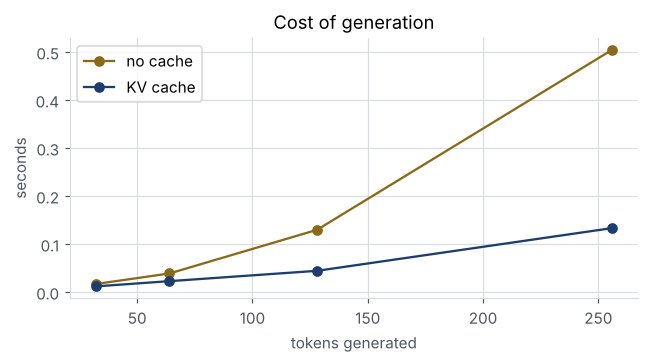

In [5]:
rows = exp_kv_cache()
print("new tokens   with cache (s)   without cache (s)   speed-up   same output   cache size (KB)")
for r in rows:
    print(f"{r['new_tokens']:10d} {r['with_cache_s']:16.3f} {r['without_cache_s']:19.3f} {r['without_cache_s'] / r['with_cache_s']:10.1f} {str(r['same_output']):>13s} {r['cache_kb']:17.1f}")
n = [r["new_tokens"] for r in rows]
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.plot(n, [r["without_cache_s"] for r in rows], marker="o", color=AMBER, label="no cache"); ax.plot(n, [r["with_cache_s"] for r in rows], marker="o", color=NAVY, label="KV cache")
ax.set_xlabel("tokens generated"); ax.set_ylabel("seconds"); ax.legend(); ax.set_title("Cost of generation"); plt.tight_layout(); plt.show()

The output is identical, so the cache is a pure efficiency gain. Without the cache the cost grows roughly with the *square* of the length, because step $t$ reprocesses $t$ tokens. With the cache the cost grows roughly linearly: each step handles one token plus a look-up over the stored keys and values. The price is memory. The cache holds two vectors per layer per token, so it grows linearly with the sequence length and with the batch size, and for a large model with a long context it is often the part that limits how many users one GPU can serve.

## 2. Batching

In [6]:
Xtr, ytr, Xte, yte = load_digits_split(0)
net = train(mlp([64, 512, 512, 10]), Xtr, ytr, epochs=30, seed=0).eval()
st = service_time_table(net, Xtr)
st = dict(zip(st, np.maximum.accumulate(list(st.values()))))        # a bigger batch never takes less time
print("batch size   time per batch (ms)   time per image (ms)   images per second")
for b, t in st.items(): print(f"{b:10d} {t * 1e3:21.3f} {t / b * 1e3:21.4f} {b / t:19.0f}")

batch size   time per batch (ms)   time per image (ms)   images per second
         1                 0.043                0.0432               23151
         2                 0.043                0.0216               46301
         4                 0.055                0.0138               72254
         8                 0.076                0.0095              105415
        16                 0.148                0.0092              108440
        32                 0.229                0.0072              139699
        64                 0.405                0.0063              157911
       128                 0.772                0.0060              165910
       256                 1.437                0.0056              178182


The time for a batch grows far more slowly than the batch size, because a single image leaves most of the hardware idle: the fixed cost of launching the work is shared. So the cost per image falls and the throughput rises as the batch grows, until the hardware is busy and the curve flattens. The catch is that a request that joins a batch must wait for it to fill and then for the whole batch to finish.

## 3. A latency budget

We simulate a server with random (Poisson) arrivals. Requests are collected until the batch is full or the oldest has waited `max_wait`, then the batch is run using the measured times above. The arrival rate is set at 1.5 times what the server could handle one image at a time, so one-at-a-time serving cannot keep up.

In [7]:
s1 = st[1]; rate = 1.5 / s1
print(f"single-image capacity {1 / s1:.0f} per second;  arrival rate {rate:.0f} per second\n")
print("max batch   max wait (ms)   median latency (ms)   95th percentile (ms)   throughput (per s)")
res = []
for mb, mw in ((1, 0), (4, 0.5 * s1), (16, s1), (64, 2 * s1), (256, 4 * s1), (256, 40 * s1)):
    p50, p95, tp = simulate_server(st, rate, mb, mw); res.append((mb, mw, p50, p95, tp))
    print(f"{mb:9d} {mw * 1e3:15.3f} {p50 * 1e3:21.3f} {p95 * 1e3:22.3f} {tp:20.0f}")
budget = 20 * s1
ok = [r for r in res if r[3] <= budget]
print(f"\nWith a 95th-percentile budget of {budget * 1e3:.2f} ms, configurations that meet it:", [(r[0], round(r[1] * 1e3, 3)) for r in ok])

single-image capacity 23151 per second;  arrival rate 34726 per second

max batch   max wait (ms)   median latency (ms)   95th percentile (ms)   throughput (per s)
        1           0.000                28.189                 52.508                23144
        4           0.022                 0.069                  0.100                34054
       16           0.043                 0.086                  0.114                34048
       64           0.086                 0.126                  0.162                34045
      256           0.173                 0.202                  0.314                34025
      256           1.728                 1.390                  2.141                33921

With a 95th-percentile budget of 0.86 ms, configurations that meet it: [(4, np.float64(0.022)), (16, np.float64(0.043)), (64, np.float64(0.086)), (256, np.float64(0.173))]


With one request at a time the queue grows without limit and the latency is enormous: the server is simply overloaded. A small batch with a very short wait fixes that at almost no latency cost, and every extra increase in batch size or waiting time then *adds* latency without adding throughput, because the arrival rate, not the hardware, has become the limit. The last row shows the cost of a long wait: requests sit in the queue for no benefit. A latency budget turns this into a decision: choose the *smallest* batch and wait that meet the budget, and keep the rest of the budget as headroom for bursts.

## 4. ONNX export and ONNX Runtime

ONNX is a framework-neutral file format for a trained network. Exporting gives a model that can be served without Python or PyTorch, by ONNX Runtime and many other engines. We export the classifier with a dynamic batch dimension, check it gives the same answers, and time it.

In [8]:
path = "digits_mlp.onnx"
size = export_onnx(net, path)
sess = ort_session(path)
with torch.no_grad(): ref = net(Xte).numpy()
out = sess.run(None, {"x": Xte.numpy()})[0]
print(f"ONNX file: {size / 1024:.0f} KB;  largest difference from PyTorch logits: {np.abs(out - ref).max():.2e};  same predictions: {bool((out.argmax(1) == ref.argmax(1)).all())}")
print()
print("batch   PyTorch (ms)   ONNX Runtime (ms)")
for b in (1, 16, 256):
    xb = Xte[:b]; xn = xb.numpy()
    with torch.no_grad(): tp = timeit(lambda: net(xb), repeats=200, warmup=20)
    to = timeit(lambda: sess.run(None, {"x": xn}), repeats=200, warmup=20)
    print(f"{b:5d} {tp * 1e3:14.3f} {to * 1e3:19.3f}")
os.remove(path)

ONNX file: 1177 KB;  largest difference from PyTorch logits: 0.00e+00;  same predictions: True

batch   PyTorch (ms)   ONNX Runtime (ms)
    1          0.040               0.018


   16          0.155               0.080


/tmp/ipykernel_1047/1806693220.py:114: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(model, torch.zeros(1, in_dim), path, input_names=["x"], output_names=["logits"],


  256          1.468               1.263


The exported network gives the same logits as PyTorch here (the largest difference printed is zero, in general expect differences near float rounding) and the same predictions on every test image. Speed is a separate question and depends on the model and the hardware. On this machine ONNX Runtime is about twice as fast on one image and on a batch of 16, and only about 15% faster on a batch of 256: for a tiny network most of the gain is the removal of Python and framework overhead, which matters less as the batch grows. Larger gains come from graph optimizations on bigger models and from the int8 kernels of the quantized formats, which Lab 10 lets you try. Always check that an exported model reproduces the original *before* you trust any speed number from it.

**Try it.** Change the arrival rate to 0.5 times the single-image capacity and see whether batching is still needed. Vary `layers` in `TinyDecoder` and watch the cache size. Export the decoder's feed-forward block by itself.